# 08 — Modelos de Machine Learning
## Pipeline CAD-TBX11K | Diagnóstico Asistido por Computador en Tuberculosis

Este notebook entrena y compara los cinco modelos usando **todas las imágenes**
(8256) y **validación cruzada anidada**. No hay hold-out ni test separado.

### Protocolo
1. **CV externa 5-fold sobre las 8256**; cada imagen se valida exactamente una vez
   (predicciones out-of-fold).
2. En cada fold externo, el **selector de características del 06 se ajusta solo con el
   train del fold** y transforma train/validación.
3. **CV interna 3-fold** sobre el train del fold para ajustar hiperparámetros.
4. Se guardan las **predicciones out-of-fold** de los cinco modelos para el notebook 09.
5. El **modelo final** se reajusta con las 8256 imágenes (selector + modelo).

> Nota metodológica: el selector se ajusta una vez por fold externo, con el train de ese
> fold. El fold externo de validación nunca participa en la selección. La CV interna usa
> las features seleccionadas con el train externo; su optimismo afecta solo a la elección
> de hiperparámetros, no a la estimación out-of-fold del fold externo.

### Modelos
| Modelo | Familia | Grid |
|---|---|---|
| Regresión Logística | Lineal | `C` |
| SVM (kernel lineal) | Margen | `C` |
| Árbol de decisión | Árbol | `max_depth`, `ccp_alpha` |
| Random Forest | Bagging | `max_features`, `min_samples_leaf` |
| XGBoost | Boosting | `max_depth`, `learning_rate` |
| Dummy | Baseline | — |

### Flujo

```
X_full.npy / y_full.npy (8256)
data/06_seleccion.json  (metodo + N)
data/07_estrategia.json (estrategia)
         |
         v
 CV externa 5-fold: selector dentro del fold -> CV interna 3-fold
         |
         v
 Predicciones out-of-fold (8256) + modelos finales (8256)
         |
         v
 models/08_*.joblib + data/08_oof_*
         |
         v
     Notebook 09
  Evaluacion y comparacion (OOF)
```


## 0. Configuración del entorno


In [21]:
# Se configura el path del proyecto y se importan las librerías necesarias.
# Referencias:
#   validación anidada: https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html
#   XGBoost: https://xgboost.readthedocs.io/en/stable/

import sys, os, warnings, time, json
warnings.filterwarnings('ignore')

from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    balanced_accuracy_score, f1_score, recall_score,
    roc_auc_score, average_precision_score,
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

try:
    from xgboost import XGBClassifier
    import xgboost
except ImportError as exc:
    raise ImportError(
        'XGBoost no está instalado. Ejecuta: pip install xgboost'
    ) from exc

_CWD = Path.cwd()
PROJECT_ROOT = str(_CWD.parent if _CWD.name == 'notebooks' else _CWD)
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.config import FEATURE_MODE, INTENSITY_NORM
from src.features import model_feature_columns
from src.selection import build_selector
from src.visualization import set_publication_style

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

CLASS_NAMES   = ['health', 'sick', 'tb']
N_FOLDS_OUTER = 5
N_FOLDS_INNER = 3

DATA_DIR   = Path(PROJECT_ROOT) / 'data'
MODELS_DIR = Path(PROJECT_ROOT) / 'models'
MODELS_DIR.mkdir(exist_ok=True)

MODEL_SLUGS = {
    'Logistic Regression': 'logistic_regression',
    'SVM': 'svm',
    'Decision Tree': 'decision_tree',
    'Random Forest': 'random_forest',
    'XGBoost': 'xgboost',
    'Dummy': 'dummy',
}

set_publication_style()
print('Entorno configurado correctamente.')
print(f'scikit-learn {sklearn.__version__} | XGBoost {xgboost.__version__}')


Entorno configurado correctamente.
scikit-learn 1.9.1 | XGBoost 3.4.1


## 1. Carga de las 8256 imágenes y de las decisiones previas


In [22]:
# Se cargan las 8256 imágenes (sin split), la selección del 06 y la estrategia del 07.
# Referencia: https://numpy.org/doc/stable/reference/generated/numpy.load.html

for archivo in ['X_full.npy', 'y_full.npy', '06_seleccion.json', '07_estrategia.json']:
    if not (DATA_DIR / archivo).exists():
        raise FileNotFoundError(
            f'No se encontró {archivo}. Ejecuta primero los notebooks 06 y 07.'
        )

X = np.load(DATA_DIR / 'X_full.npy')
y = np.load(DATA_DIR / 'y_full.npy')

with open(DATA_DIR / '06_seleccion.json', encoding='utf-8') as f:
    seleccion = json.load(f)
with open(DATA_DIR / '07_estrategia.json', encoding='utf-8') as f:
    decision = json.load(f)

METHOD_SEL = seleccion['metodo']
N_SEL      = int(seleccion['n_features'])
ESTRATEGIA = decision['estrategia']

print(f'X: {X.shape} ({X.dtype})')
print(f'y : {y.shape}')
print()
print('Distribución:')
for clase, conteo in zip(*np.unique(y, return_counts=True)):
    print(f'  {CLASS_NAMES[clase]:6s} (label={clase}): {conteo} muestras')
print()
print(f'Selector   : {METHOD_SEL}, N={N_SEL}')
print(f'Estrategia : {ESTRATEGIA}')


X: (8256, 1832) (float32)
y : (8256,)

Distribución:
  health (label=0): 3800 muestras
  sick   (label=1): 3656 muestras
  tb     (label=2): 800 muestras

Selector   : RF, N=300
Estrategia : class_weight


## 2. Selector, modelos y grids


In [23]:
# El selector se ajusta dentro de cada fold externo. Los modelos se envuelven en
# Pipeline para que los grids usen siempre el prefijo 'clf__'.
# Referencia: https://scikit-learn.org/stable/modules/grid_search.html

selector_base = build_selector(
    METHOD_SEL, N_SEL, random_state=RANDOM_STATE, n_jobs=-1,
)


def _pipeline(clf, escalar, estrategia):
    pasos = []
    if escalar:
        pasos.append(('scaler', StandardScaler()))
    if estrategia == 'SMOTE':
        pasos.append(('smote', SMOTE(random_state=RANDOM_STATE)))
    pasos.append(('clf', clf))
    return ImbPipeline(pasos) if estrategia == 'SMOTE' else Pipeline(pasos)


def construir_modelos(estrategia):
    cw   = 'balanced' if estrategia == 'class_weight' else None
    rfcw = 'balanced_subsample' if estrategia == 'class_weight' else None

    return {
        'Logistic Regression': _pipeline(
            LogisticRegression(class_weight=cw, max_iter=1000, random_state=RANDOM_STATE),
            True, estrategia,
        ),
        'SVM': _pipeline(
            SVC(kernel='linear', class_weight=cw, cache_size=500, random_state=RANDOM_STATE),
            True, estrategia,
        ),
        'Decision Tree': _pipeline(
            DecisionTreeClassifier(
                class_weight=cw, max_depth=12, min_samples_leaf=5,
                random_state=RANDOM_STATE,
            ),
            False, estrategia,
        ),
        'Random Forest': _pipeline(
            RandomForestClassifier(
                n_estimators=300, class_weight=rfcw, max_features='sqrt',
                n_jobs=-1, random_state=RANDOM_STATE,
            ),
            False, estrategia,
        ),
        'XGBoost': _pipeline(
            XGBClassifier(
                n_estimators=300, max_depth=6, learning_rate=0.1,
                subsample=0.8, colsample_bytree=0.8,
                objective='multi:softprob', num_class=len(CLASS_NAMES),
                eval_metric='mlogloss', tree_method='hist',
                n_jobs=-1, random_state=RANDOM_STATE,
            ),
            False, estrategia,
        ),
    }


def construir_grids():
    return {
        'Logistic Regression': {'clf__C': [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]},
        'SVM': {'clf__C': [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]},
        'Decision Tree': {
            'clf__max_depth': [6, 8, 12],
            'clf__ccp_alpha': [0.0, 0.001],
        },
        'Random Forest': {
            'clf__max_features': [0.1, 0.2],
            'clf__min_samples_leaf': [5, 10],
        },
        'XGBoost': {
            'clf__max_depth': [2, 3],
            'clf__learning_rate': [0.1],
        },
    }


MODELOS = construir_modelos(ESTRATEGIA)
GRIDS   = construir_grids()

print(f'Selector: {METHOD_SEL}, N={N_SEL}')
print(f'Estrategia: {ESTRATEGIA}')
for nombre, grid in GRIDS.items():
    print(f'  {nombre:22s} {grid}')


Selector: RF, N=300
Estrategia: class_weight
  Logistic Regression    {'clf__C': [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]}
  SVM                    {'clf__C': [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]}
  Decision Tree          {'clf__max_depth': [6, 8, 12], 'clf__ccp_alpha': [0.0, 0.001]}
  Random Forest          {'clf__max_features': [0.1, 0.2], 'clf__min_samples_leaf': [5, 10]}
  XGBoost                {'clf__max_depth': [2, 3], 'clf__learning_rate': [0.1]}


## 3. Validación cruzada anidada y predicciones out-of-fold

La CV externa es 5-fold sobre las 8256. En cada fold externo se hace una CV interna 3-fold
para hiperparámetros. **En cada fold interno el selector se reajusta solo con el train
interno**; el fold externo se predice con el selector ajustado con el train externo.

El selector es el mismo para los cinco modelos en un fold dado, así que se ajusta **una vez
por fold** y se reutiliza. Es una optimización exacta de cómputo, no una aproximación.

Los grids son pequeños y se mantienen dentro de la CV interna: LR/SVM (`C`), DT
(`max_depth`, `ccp_alpha`), RF (`max_features`, `min_samples_leaf`) y XGB
(`max_depth`, `learning_rate`). No se fijan hiperparámetros a partir de corridas previas.

También se calcula una estimación OOF del **procedimiento completo** (selector +
hiperparámetros + selección de modelo): en cada fold externo se elige el modelo con mejor
score interno y se evalúa en el fold externo.

> **Nota sobre la grilla de SVM:** `C=0.003` es el límite inferior de la grilla usada en esta
> corrida. En una re-ejecución conviene extenderla a `0.001` y `0.0003`; los resultados
> actuales corresponden a la grilla original y deben interpretarse con esa limitación.


In [24]:
# CV externa 5-fold con CV interna 3-fold.
#
# El selector no depende del modelo: para el mismo fold y el mismo metodo/N es
# identico para LR, SVM, DT, RF y XGBoost. Por eso se ajusta UNA vez por fold
# (externo e interno) y se reutiliza para los 5 modelos. Es una optimizacion
# exacta de computo, no una aproximacion.
#
# En cada fold interno el selector se ajusta SOLO con su train interno.
# El fold externo se predice con el selector ajustado solo con su train externo.

from sklearn.model_selection import ParameterGrid

cv_outer = StratifiedKFold(n_splits=N_FOLDS_OUTER, shuffle=True, random_state=RANDOM_STATE)
cv_inner = StratifiedKFold(n_splits=N_FOLDS_INNER, shuffle=True, random_state=RANDOM_STATE)


def calcular_metricas(y_true, y_pred, y_score):
    return {
        'Balanced Acc': balanced_accuracy_score(y_true, y_pred),
        'F1 macro': f1_score(y_true, y_pred, average='macro'),
        'Recall tb': recall_score(y_true, y_pred, labels=[2], average=None)[0],
        'AUC-ROC macro': np.mean([
            roc_auc_score((y_true == c).astype(int), y_score[:, c])
            for c in range(len(CLASS_NAMES))
        ]),
        'AP tb': average_precision_score((y_true == 2).astype(int), y_score[:, 2]),
    }


def ajustar_modelo(nombre, modelo, X, y):
    if nombre == 'XGBoost' and ESTRATEGIA == 'class_weight':
        modelo.fit(X, y, clf__sample_weight=compute_sample_weight('balanced', y))
    else:
        modelo.fit(X, y)
    return modelo


oof_pred = {n: np.full(len(y), -1, dtype=int) for n in list(MODELOS) + ['Dummy']}
oof_score = {n: np.full((len(y), len(CLASS_NAMES)), np.nan) for n in list(MODELOS) + ['Dummy']}
best_params_fold = {n: [] for n in MODELOS}
fold_rows = {n: [] for n in MODELOS}
t_model = {n: 0.0 for n in MODELOS}
selected_per_fold = {}
inner_mean_by_model = {}
proc_pred = np.full(len(y), -1, dtype=int)
proc_score = np.full((len(y), len(CLASS_NAMES)), np.nan)

for fold, (tr_idx, va_idx) in enumerate(cv_outer.split(X, y), start=1):
    # Selector del fold externo (una sola vez).
    selector_out = clone(selector_base).fit(X[tr_idx], y[tr_idx])
    X_tr = selector_out.transform(X[tr_idx])
    X_va = selector_out.transform(X[va_idx])
    y_tr, y_va = y[tr_idx], y[va_idx]

    # Selectores de los folds internos (una sola vez por fold interno).
    inner_cache = []
    for in_tr, in_va in cv_inner.split(X[tr_idx], y[tr_idx]):
        gi_tr, gi_va = tr_idx[in_tr], tr_idx[in_va]
        sel_in = clone(selector_base).fit(X[gi_tr], y[gi_tr])
        inner_cache.append({
            'X_tr': sel_in.transform(X[gi_tr]),
            'X_va': sel_in.transform(X[gi_va]),
            'y_tr': y[gi_tr],
            'y_va': y[gi_va],
        })

    fold_inner_mean = {}
    fold_pred = {}
    fold_score = {}

    for nombre, modelo_base in MODELOS.items():
        t0 = time.time()
        combos = list(ParameterGrid(GRIDS[nombre]))
        scores = np.zeros((len(combos), len(inner_cache)))

        for k_in, data in enumerate(inner_cache):
            for k, params in enumerate(combos):
                modelo = clone(modelo_base).set_params(**params)
                ajustar_modelo(nombre, modelo, data['X_tr'], data['y_tr'])
                scores[k, k_in] = balanced_accuracy_score(
                    data['y_va'], modelo.predict(data['X_va'])
                )

        mean_scores = scores.mean(axis=1)
        best_k = int(np.argmax(mean_scores))
        best_params = combos[best_k]
        best_params_fold[nombre].append(best_params)
        fold_inner_mean[nombre] = float(mean_scores[best_k])

        modelo = clone(modelo_base).set_params(**best_params)
        ajustar_modelo(nombre, modelo, X_tr, y_tr)
        y_pred = modelo.predict(X_va)
        y_score = (modelo.predict_proba(X_va) if hasattr(modelo, 'predict_proba')
                   else modelo.decision_function(X_va))

        oof_pred[nombre][va_idx] = y_pred
        oof_score[nombre][va_idx] = y_score
        fold_pred[nombre] = y_pred
        fold_score[nombre] = y_score

        fold_rows[nombre].append({
            'Modelo': nombre, 'Fold': fold,
            **calcular_metricas(y_va, y_pred, y_score),
            'Mejores params': json.dumps(best_params, sort_keys=True),
        })
        t_model[nombre] += time.time() - t0
        print(f'fold {fold}/{N_FOLDS_OUTER}  {nombre:22s}  '
              f'inner={mean_scores[best_k]:.4f}')

    best_model = max(fold_inner_mean, key=fold_inner_mean.get)
    selected_per_fold[fold] = best_model
    inner_mean_by_model[fold] = fold_inner_mean
    proc_pred[va_idx] = fold_pred[best_model]
    proc_score[va_idx] = fold_score[best_model]

# Resumen por modelo (OOF).
filas_fold = []
filas_resumen = []
mejores_params = {}

for nombre in MODELOS:
    filas_fold.extend(fold_rows[nombre])
    df_fold = pd.DataFrame(fold_rows[nombre])
    oof_m = calcular_metricas(y, oof_pred[nombre], oof_score[nombre])
    resumen = {
        'Modelo': nombre,
        **{f'{k}_oof': v for k, v in oof_m.items()},
        'Tiempo_s': t_model[nombre],
    }
    for k in ['Balanced Acc', 'F1 macro', 'Recall tb', 'AUC-ROC macro', 'AP tb']:
        resumen[f'{k}_media'] = df_fold[k].mean()
        resumen[f'{k}_std'] = df_fold[k].std()
    filas_resumen.append(resumen)

    clave = Counter(json.dumps(p, sort_keys=True) for p in best_params_fold[nombre]).most_common(1)[0][0]
    mejores_params[nombre] = json.loads(clave)

    print(f'{nombre:22s}  OOF BalAcc={oof_m["Balanced Acc"]:.4f}  '
          f'F1={oof_m["F1 macro"]:.4f}  Recall tb={oof_m["Recall tb"]:.4f}  '
          f'({t_model[nombre]:.1f}s)')

# Guardado intermedio: preserva los 5 modelos si falla el Dummy o el procedimiento.
pd.DataFrame({'y_true': y, **{n: oof_pred[n] for n in MODELOS}}).to_csv(
    DATA_DIR / '08_oof_predicciones.csv', index=False,
)
np.savez(DATA_DIR / '08_oof_scores.npz', **{n: oof_score[n] for n in MODELOS})
pd.DataFrame(filas_fold).to_csv(DATA_DIR / '08_cv_por_fold.csv', index=False)
with open(DATA_DIR / '08_mejores_params.json', 'w', encoding='utf-8') as f:
    json.dump(mejores_params, f, ensure_ascii=False, indent=2)
print('Resultados OOF de los 5 modelos guardados (intermedio).')

# Dummy: baseline trivial, sin selector ni grid.
dummy = DummyClassifier(strategy='most_frequent')
t0 = time.time()
dummy_rows = []
for fold, (tr_idx, va_idx) in enumerate(cv_outer.split(X, y), start=1):
    dummy.fit(X[tr_idx], y[tr_idx])
    y_pred = dummy.predict(X[va_idx])
    y_score = dummy.predict_proba(X[va_idx])
    oof_pred['Dummy'][va_idx] = y_pred
    oof_score['Dummy'][va_idx] = y_score
    fila = {'Modelo': 'Dummy', 'Fold': fold,
            **calcular_metricas(y[va_idx], y_pred, y_score),
            'Mejores params': '{}'}
    dummy_rows.append(fila)
    filas_fold.append(fila)

df_dummy = pd.DataFrame(dummy_rows)
oof_m = calcular_metricas(y, oof_pred['Dummy'], oof_score['Dummy'])
filas_resumen.append({
    'Modelo': 'Dummy', **{f'{k}_oof': v for k, v in oof_m.items()},
    'Tiempo_s': time.time() - t0,
    **{f'{k}_media': df_dummy[k].mean() for k in ['Balanced Acc', 'F1 macro', 'Recall tb', 'AUC-ROC macro', 'AP tb']},
    **{f'{k}_std': df_dummy[k].std() for k in ['Balanced Acc', 'F1 macro', 'Recall tb', 'AUC-ROC macro', 'AP tb']},
})
mejores_params['Dummy'] = {}
print(f'{"Dummy":22s}  OOF BalAcc={oof_m["Balanced Acc"]:.4f}')

# Estimación OOF del procedimiento completo.
proc_metrics = calcular_metricas(y, proc_pred, proc_score)
# Los scores del procedimiento mezclan decision_function (SVM) y
# probabilidades; AP y AUC no son comparables. Se reportan solo
# métricas basadas en etiquetas.
proc_metrics['AUC-ROC macro'] = np.nan
proc_metrics['AP tb'] = np.nan
filas_resumen.append({
    'Modelo': 'Procedimiento', **{f'{k}_oof': v for k, v in proc_metrics.items()},
    'Tiempo_s': np.nan,
    **{f'{k}_media': np.nan for k in ['Balanced Acc', 'F1 macro', 'Recall tb', 'AUC-ROC macro', 'AP tb']},
    **{f'{k}_std': np.nan for k in ['Balanced Acc', 'F1 macro', 'Recall tb', 'AUC-ROC macro', 'AP tb']},
})

resumen_oof = pd.DataFrame(filas_resumen).sort_values(
    ['Balanced Acc_oof', 'Recall tb_oof', 'AP tb_oof'], ascending=False,
).reset_index(drop=True)
por_fold = pd.DataFrame(filas_fold)

print()
print('Resumen out-of-fold (8256 imágenes):')
print(resumen_oof.round(4).to_string(index=False))
print()
print('Modelo seleccionado en cada fold externo:', selected_per_fold)
print(f'Procedimiento (OOF): BalAcc={proc_metrics["Balanced Acc"]:.4f}, '
      f'F1={proc_metrics["F1 macro"]:.4f}, Recall tb={proc_metrics["Recall tb"]:.4f}')

resumen_oof.to_csv(DATA_DIR / '08_cv_resumen.csv', index=False)
por_fold.to_csv(DATA_DIR / '08_cv_por_fold.csv', index=False)
with open(DATA_DIR / '08_mejores_params.json', 'w', encoding='utf-8') as f:
    json.dump(mejores_params, f, ensure_ascii=False, indent=2)
with open(DATA_DIR / '08_procedimiento.json', 'w', encoding='utf-8') as f:
    json.dump({
        'selected_per_fold': selected_per_fold,
        'metricas_oof': {
            k: (None if not np.isfinite(v) else float(v))
            for k, v in proc_metrics.items()
        },
    }, f, ensure_ascii=False, indent=2)

pd.DataFrame({'y_true': y, **{n: oof_pred[n] for n in MODELOS}}).to_csv(
    DATA_DIR / '08_oof_predicciones.csv', index=False,
)
pd.DataFrame({'y_true': y, 'procedimiento': proc_pred}).to_csv(
    DATA_DIR / '08_oof_procedimiento.csv', index=False,
)
np.savez(DATA_DIR / '08_oof_scores.npz', **{n: oof_score[n] for n in MODELOS})

print()
print('Predicciones y scores OOF guardados.')


fold 1/5  Logistic Regression     inner=0.8650
fold 1/5  SVM                     inner=0.8597
fold 1/5  Decision Tree           inner=0.7372
fold 1/5  Random Forest           inner=0.8016
fold 1/5  XGBoost                 inner=0.8559
fold 2/5  Logistic Regression     inner=0.8674
fold 2/5  SVM                     inner=0.8654
fold 2/5  Decision Tree           inner=0.7379
fold 2/5  Random Forest           inner=0.8036
fold 2/5  XGBoost                 inner=0.8550
fold 3/5  Logistic Regression     inner=0.8672
fold 3/5  SVM                     inner=0.8603
fold 3/5  Decision Tree           inner=0.7305
fold 3/5  Random Forest           inner=0.8026
fold 3/5  XGBoost                 inner=0.8480
fold 4/5  Logistic Regression     inner=0.8683
fold 4/5  SVM                     inner=0.8676
fold 4/5  Decision Tree           inner=0.7476
fold 4/5  Random Forest           inner=0.8060
fold 4/5  XGBoost                 inner=0.8486
fold 5/5  Logistic Regression     inner=0.8729
fold 5/5  SVM

## 4. Selección y persistencia de los modelos finales


Modelo seleccionado por CV OOF: Logistic Regression
  BalAcc OOF : 0.8757
  Recall tb  : 0.7987
  AP tb      : 0.7509


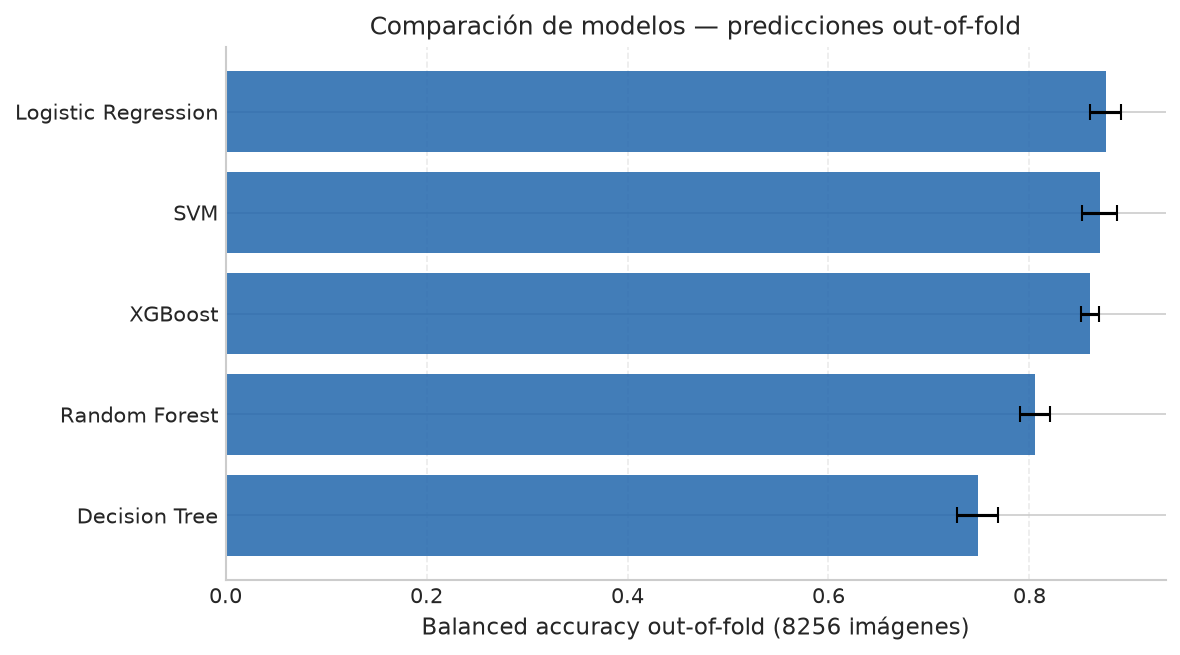

Logistic Regression    -> 08_logistic_regression.joblib  (0.0 MB)
SVM                    -> 08_svm.joblib  (5.3 MB)
Decision Tree          -> 08_decision_tree.joblib  (0.0 MB)
Random Forest          -> 08_random_forest.joblib  (10.7 MB)
XGBoost                -> 08_xgboost.joblib  (0.8 MB)

Manifiesto guardado en: C:\Users\estra\Desktop\Tuberculosis\cad-tbx11k\models\08_manifest.json
Modelo seleccionado: Logistic Regression


In [25]:
# Selección por OOF: balanced accuracy > recall tb > AP tb. El Dummy se excluye.
candidatos = resumen_oof[
    ~resumen_oof['Modelo'].isin(['Dummy', 'Procedimiento'])
].reset_index(drop=True)
MEJOR_MODELO_CV = candidatos.loc[0, 'Modelo']

print(f'Modelo seleccionado por CV OOF: {MEJOR_MODELO_CV}')
print(f'  BalAcc OOF : {candidatos.loc[0, "Balanced Acc_oof"]:.4f}')
print(f'  Recall tb  : {candidatos.loc[0, "Recall tb_oof"]:.4f}')
print(f'  AP tb      : {candidatos.loc[0, "AP tb_oof"]:.4f}')

fig, ax = plt.subplots(figsize=(8, 4.5))
orden = candidatos.sort_values('Balanced Acc_oof')
ax.barh(orden['Modelo'], orden['Balanced Acc_oof'],
        xerr=orden['Balanced Acc_std'], capsize=4, color='#2166AC', alpha=0.85)
ax.set_xlabel('Balanced accuracy out-of-fold (8256 imágenes)', fontsize=11)
ax.set_title('Comparación de modelos — predicciones out-of-fold', fontsize=12)
ax.grid(True, axis='x', linestyle='--', alpha=0.4)
fig.tight_layout()
plt.show()

# Modelos finales: selector + modelo, ajustados con las 8256 imágenes.
manifest = {
    'estrategia': ESTRATEGIA,
    'selector': {'metodo': METHOD_SEL, 'n_features': N_SEL},
    'modelos': {},
    'seleccionado_cv': MEJOR_MODELO_CV,
    'mejores_params': mejores_params,
}

for nombre in MODELOS:
    base = clone(MODELOS[nombre]).set_params(**mejores_params[nombre])
    selector = build_selector(
    METHOD_SEL, N_SEL, random_state=RANDOM_STATE, n_jobs=-1,
)
    Final = ImbPipeline if isinstance(base, ImbPipeline) else Pipeline
    final = Final([('selector', selector)] + list(base.steps))

    if nombre == 'XGBoost' and ESTRATEGIA == 'class_weight':
        final.fit(X, y, clf__sample_weight=compute_sample_weight('balanced', y))
    else:
        final.fit(X, y)

    archivo = f'08_{MODEL_SLUGS[nombre]}.joblib'
    ruta = MODELS_DIR / archivo
    joblib.dump(final, ruta)
    manifest['modelos'][nombre] = archivo
    print(f'{nombre:22s} -> {archivo}  ({ruta.stat().st_size / 1024 / 1024:.1f} MB)')

with open(MODELS_DIR / '08_manifest.json', 'w', encoding='utf-8') as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)

print()
print(f'Manifiesto guardado en: {(MODELS_DIR / "08_manifest.json").resolve()}')
print(f'Modelo seleccionado: {MEJOR_MODELO_CV}')


In [26]:
# Umbrales binarios TB vs resto a partir de las predicciones OOF.
# Se guardan para que el CAD pueda reportar "TB positivo" con una sensibilidad
# objetivo, no solo con argmax.
y_tb = (y == 2).astype(int)


def _metricas_binarias(y_true, score, threshold):
    yhat = (score >= threshold).astype(int)
    tp = int(((yhat == 1) & (y_true == 1)).sum())
    fn = int(((yhat == 0) & (y_true == 1)).sum())
    tn = int(((yhat == 0) & (y_true == 0)).sum())
    fp = int(((yhat == 1) & (y_true == 0)).sum())
    sens = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1)
    return sens, spec


filas_umbral = []
for nombre in MODELOS:
    scores = oof_score[nombre]
    if np.isnan(scores).any() or nombre == 'SVM':
        continue
    p_tb = scores[:, 2]
    thresholds = np.unique(np.round(p_tb, 6))

    best_t, best_j = 0.5, -1.0
    for t in thresholds:
        sens, spec = _metricas_binarias(y_tb, p_tb, t)
        j = sens + spec - 1
        if j > best_j:
            best_j, best_t = j, float(t)
    sens_y, spec_y = _metricas_binarias(y_tb, p_tb, best_t)

    thr90 = 0.5
    for t in thresholds[::-1]:
        sens, _ = _metricas_binarias(y_tb, p_tb, t)
        if sens >= 0.90:
            thr90 = float(t)
            break
    sens90, spec90 = _metricas_binarias(y_tb, p_tb, thr90)

    filas_umbral.append({
        'Modelo': nombre,
        'threshold_youden': best_t,
        'sens_youden': sens_y,
        'spec_youden': spec_y,
        'threshold_sens90': thr90,
        'sens_sens90': sens90,
        'spec_sens90': spec90,
    })

umbrales_tb = pd.DataFrame(filas_umbral).sort_values('Modelo').reset_index(drop=True)
umbrales_tb.to_csv(DATA_DIR / '08_umbrales_tb.csv', index=False)

fila_sel = umbrales_tb[umbrales_tb['Modelo'] == MEJOR_MODELO_CV]
if not fila_sel.empty:
    umbral_sel = {
        'modelo': MEJOR_MODELO_CV,
        'tipo': 'orientativo_oof',
        'clase': 'tb',
        'threshold_youden': float(fila_sel.iloc[0]['threshold_youden']),
        'threshold_sens90': float(fila_sel.iloc[0]['threshold_sens90']),
        'sens_sens90': float(fila_sel.iloc[0]['sens_sens90']),
        'spec_sens90': float(fila_sel.iloc[0]['spec_sens90']),
    }
    with open(MODELS_DIR / '08_umbral_tb.json', 'w', encoding='utf-8') as f:
        json.dump(umbral_sel, f, ensure_ascii=False, indent=2)

umbrales_tb.round(4)


,Modelo,threshold_youden,sens_youden,spec_youden,threshold_sens90,sens_sens90,spec_sens90
0,Decision Tree,0.2073,0.6825,0.8299,0.0143,0.9012,0.1139
1,Logistic Regression,0.3338,0.8738,0.9069,0.1921,0.9000,0.8553
2,Random Forest,0.2212,0.8625,0.8405,0.1815,0.9000,0.7874
3,XGBoost,0.2271,0.8750,0.8710,0.1776,0.9000,0.8443


In [27]:
# Esquema que debe usar cualquier CAD para que las features coincidan con el modelo.

feature_columns = model_feature_columns(
    pd.read_csv(DATA_DIR / 'features_tbx11k.csv', nrows=0)
)
schema = {
    'class_names': CLASS_NAMES,
    'feature_columns': feature_columns,
    'n_features': len(feature_columns),
    'intensity_norm': INTENSITY_NORM,
    'feature_mode': FEATURE_MODE,
    'excluded_intensity': True,
    'preprocessing': 'recorte toracico segmentado + HOG enmascarado (mediana pulmonar)',
    'selector': {'metodo': METHOD_SEL, 'n_features': N_SEL},
    'strategy': ESTRATEGIA,
    'selected_model': MEJOR_MODELO_CV,
    'models': manifest['modelos'],
}
with open(MODELS_DIR / '08_feature_schema.json', 'w', encoding='utf-8') as f:
    json.dump(schema, f, ensure_ascii=False, indent=2)

print(f'Esquema de features guardado: {len(feature_columns)} columnas')


Esquema de features guardado: 1832 columnas


## Conclusiones

Se usaron **todas las imágenes** (8256). No hay hold-out ni test separado: la estimación
es la **predicción out-of-fold** de una CV externa 5-fold.

En cada fold externo, el selector de características se ajustó **solo con el train** y la
CV interna 3-fold ajustó los hiperparámetros. Las predicciones out-of-fold cubren las 8256
imágenes exactamente una vez.

El modelo final de cada algoritmo (selector + modelo) se reajustó con las 8256 imágenes.
Los artefactos `08_oof_predicciones.csv` y `08_oof_scores.npz` son la base de la evaluación
del notebook 09.


**Siguiente etapa:** `09_Evaluacion_Comparativa.ipynb`
